# 05 · XS-target PCA (Bryzgalova, DeMiguel, Li & Pelger, 2026)

**Purpose.** Make latent factors *economically interpretable*: tilt their
loadings and portfolio weights towards a cross-sectional target space
$\Lambda^{XS}$ ($N\times L$) — e.g. characteristic "shape" patterns or exposures
to macroeconomic shocks.

**Specification (Proposition 1).** Top-$K$ eigenvectors $Q_K$ of
$\frac1{NT}CR'RC$ with $C=I_N+\tilde\gamma P_\Lambda$,
$\tilde\gamma=\sqrt{\gamma_{XS}N/L+1}-1$; weights
$\hat\omega=CQ_K/(1+\tilde\gamma)$, loadings by OLS with intercept (eq. 13).

| Parameter | Default | Options |
|---|---|---|
| `n_factors` | 1 | number of factors |
| `gamma_xs` | 1.0 | target weight $\ge0$ (0 = second-moment PCA) |
| `xs_target` | `"given"` | `"given"` (pass `xs_target=`) or `"macro"` (pass `macro=`) |

**Outputs** in addition to the common ones: `target_metrics()` with the
XS-metric $100\lVert P_\Lambda\hat\omega\rVert/\lVert\hat\omega\rVert$ per factor
and for the SDF weights.

### How to run this notebook

```bash
pip install -e ".[notebooks]"        # package + jupyter, matplotlib, pandas
jupyter lab examples/                 # or: jupyter notebook examples/
```

All data are **synthetic with known ground truth** (generated by
`lfm.simulate_factor_returns` / `lfm.simulate_ipca_panel`), so every cell runs
offline in seconds and estimates can be compared with the truth. To use your
own data, replace the simulation cell by a `pandas.DataFrame` of excess returns
(dates x assets); every estimator accepts DataFrames directly.

In [1]:
# Setup: imports, plotting defaults and reproducibility
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import latent_factor_models as lfm

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3})
print("latent-factor-models", lfm.__version__)

latent-factor-models 0.1.0


In [2]:
sim = lfm.simulate_factor_returns(T=600, N=100, seed=0)
R, Lam = sim.returns, sim.xs_target  # Lam: noisy loadings of the weak factor (N x 1)
N, L = R.shape[1], Lam.shape[1]

## 1. Trading off fit and economic structure

Because $W_{XS}$ scales $\gamma_{XS}$ by $N/L$, grids in multiples of $L/N$ are
natural. Larger $\gamma_{XS}$ moves the SDF towards the target space.

In [3]:
grid = [0.0, 0.25 * L / N, L / N, 4 * L / N, 16 * L / N]
rows = []
for g in grid:
    m = lfm.XSTargetPCA(3, gamma_xs=g).fit(R, xs_target=Lam)
    ev, tm = m.evaluate(), m.target_metrics()
    rows.append({**ev, "XS-metric (SDF)": tm["xs_metric_sdf"], "gamma~": m.gamma_tilde_})
table = pd.DataFrame(rows, index=pd.Index(np.round(grid, 4), name="gamma_xs"))
table

,sharpe_ratio,rms_alpha,unexplained_variation,total_r2,XS-metric (SDF),gamma~
gamma_xs,,,,,,
0.0000,0.3311,0.1288,0.3371,0.7060,90.4440,0.0000
0.0025,0.3317,0.1286,0.3372,0.7060,92.9163,0.1180
0.0100,0.3320,0.1284,0.3373,0.7059,95.5391,0.4142
0.0400,0.3316,0.1284,0.3375,0.7058,96.9148,1.2361
0.1600,0.3312,0.1285,0.3376,0.7057,97.1810,3.1231


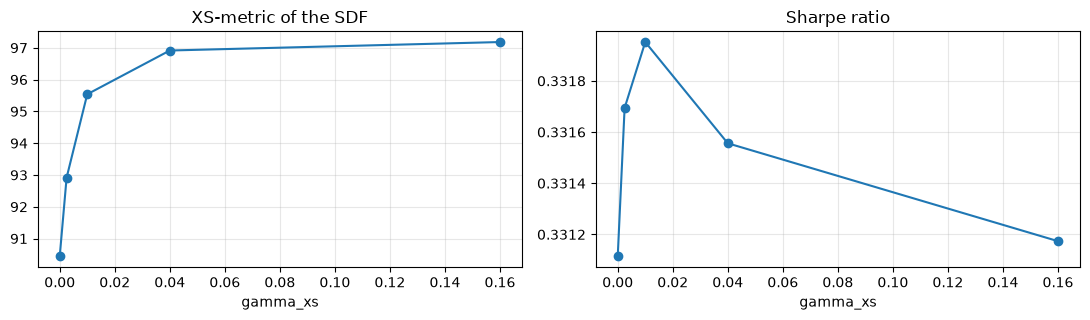

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
table["XS-metric (SDF)"].plot(ax=ax[0], marker="o", title="XS-metric of the SDF")
table["sharpe_ratio"].plot(ax=ax[1], marker="o", title="Sharpe ratio")
plt.tight_layout();

## 2. Target constructors

`latent_factor_models.models.targets` builds the paper's targets:

* `shape_target(groups, n_groups=10)` — $-1+\tfrac{2}{9}(i-1)$ for decile $i$ of each
  characteristic (footnote 12);
* `macro_target(R, Y)` — $\Lambda=R'Y(Y'Y)^{-1}$ (eq. 7);
* `macro_innovations(panel, n_components=7, var_lags=1)` — standardise, PCA,
  VAR(1) residuals, as in Section 3.5.

In [5]:
from latent_factor_models.models.targets import macro_innovations, shape_target

# a 2-characteristic decile design: asset n belongs to decile (n % 10) + 1 of both sorts
groups = np.column_stack([np.arange(N) % 10 + 1, (np.arange(N) // 10) % 10 + 1])
shape = shape_target(groups)
m_shape = lfm.XSTargetPCA(3, gamma_xs=1.0).fit(R, xs_target=shape)
print(
    "shape target:",
    shape.shape,
    "| XS-metric per factor:",
    np.round(m_shape.target_metrics()["xs_metric"], 1),
)

shape target: (100, 2) | XS-metric per factor: [ 77.7  99.7 100. ]


## 3. Macro target without look-ahead

With `xs_target="macro"` the target $R'Y(Y'Y)^{-1}$ is rebuilt **inside every
estimation window** (cross-validation folds, rolling windows), so no
future information enters the target.

In [6]:
macro_panel = np.random.default_rng(1).standard_normal((601, 20))
Y = macro_innovations(macro_panel, n_components=2, var_lags=1)  # 600 x 2 innovations
m_macro = lfm.XSTargetPCA(3, gamma_xs=L / N, xs_target="macro").fit(R, macro=sim.macro)
print("macro innovations from a raw panel:", Y.shape)
print("XS-metric per factor (macro target):", np.round(m_macro.target_metrics()["xs_metric"], 1))

macro innovations from a raw panel: (600, 2)
XS-metric per factor (macro target): [87.3 27.4 98.3]


In [7]:
gs = lfm.GridSearchCV(
    lfm.XSTargetPCA(3, xs_target="macro"), {"gamma_xs": grid}, cv=5, scoring="sharpe"
).fit(R, macro=sim.macro)
gs.best_params_, round(gs.best_score_, 4)

({'gamma_xs': 0.0}, 0.2876)

**Validation.** No public code exists; the implementation is verified against
brute-force constructions of the operator (explicit matrix square roots), the
equivalent $T\times T$ form of Proposition 1 and the paper's objective.